# Mode jump of a compressed plate with the stabilized Newton-Raphson method

A compressed flat plate that has buckled may change its buckle pattern deep in
the post-buckling regime: the equilibrium path of the first pattern ends at a
limit point, beyond which there is no nearby equilibrium with that pattern,
and the plate jumps to a pattern with more half-waves. Under load control the
Newton-Raphson method cannot pass such a jump: every increment beyond the
limit point fails, the increments are cut down to the minimum and the
analysis stops.

`structsolve.Analysis` with `NL_method = 'stabilized_NR'` keeps the load
control and solves each increment in up to three stages:

1. the Newton-Raphson iterations of
   $\boldsymbol{R} = \boldsymbol{F}_{int}(\boldsymbol{c}) - \lambda_{n+1} \boldsymbol{F}_{ext} = \boldsymbol{0}$;
2. if they fail, the iterations of the equilibrium with viscous forces in the
   pseudo-time of the load factor,

$$
\boldsymbol{F}_{int}(\boldsymbol{c})
+ \frac{\mu}{\Delta\lambda} \boldsymbol{D} (\boldsymbol{c} - \boldsymbol{c}_n)
- \lambda_{n+1} \boldsymbol{F}_{ext} = \boldsymbol{0}
$$

   with $\boldsymbol{D}$ the absolute values of the diagonal of the linear
   stiffness matrix, $\boldsymbol{c}_n$ the last accepted state and $\mu$ =
   `Analysis.stabilization_factor`, default $10^{-5}$;
3. if these converge, the Newton-Raphson iterations of $\boldsymbol{R}$
   again, from the damped state.

`Analysis.stabilization_status` records each accepted state as
`'undamped'` (stage 1) or `'corrected'` (stage 3), both equilibria of
$\boldsymbol{R}$ to the tolerance of the convergence criterion, or
`'damped'` (stage 3 failed), a state that is not an equilibrium, whose
relative residual is in `Analysis.damped_residuals`. The stages have their
own iteration control, `stabilization_max_iter` corrections without the
too-slow check of `NL_method = 'NR'`. The method and its options are
described in the documentation of structsolve
(`structsolve.stabilized_newton_raphson`).

This notebook uses the case of the test
`tests/tests_shell/test_stabilized_nr_mode_jump.py`. Units: N, mm, MPa.

In [1]:
%matplotlib inline
import time
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
from structsolve import Analysis, lb, solve
from structsolve.convergence import crisfield_weights, crisfield_zeta

from panels.shell import Shell

# from tests/tests_shell/test_stabilized_nr_mode_jump.py
E = 70e3
NU = 0.3
H = 1.
A = 130.
B = 100.
D = E*H**3/(12*(1 - NU**2))
N0 = 4*np.pi**2*D/B**2


def plate(Nxx, perturbation=True, m=12, n=10):
    s = Shell()
    s.model = 'plate_clpt_donnell'
    s.a = A
    s.b = B
    s.stack = [0.]
    s.plyt = H
    s.laminaprop = (E, NU)
    s.m = m
    s.n = n
    # simply supported; u = 0 at x = 0, v = 0 at y = 0 and y = b
    s.x1u = 0; s.x1ur = 1; s.x2u = 1; s.x2ur = 1
    s.x1v = 1; s.x1vr = 1; s.x2v = 1; s.x2vr = 1
    s.x1w = 0; s.x1wr = 1; s.x2w = 0; s.x2wr = 1
    s.y1u = 1; s.y1ur = 1; s.y2u = 1; s.y2ur = 1
    s.y1v = 0; s.y1vr = 1; s.y2v = 0; s.y2vr = 1
    s.y1w = 0; s.y1wr = 1; s.y2w = 0; s.y2wr = 1
    s.add_distr_load_fixed_x(s.a, funcx=lambda y: -Nxx, funcy=None,
                             funcz=None, cte=False)
    if perturbation:
        s.add_point_load(0.49*s.a, s.b/2, 0, 0, 3e-4*Nxx*s.b, cte=False)
    return s


def run(s, NL_method, stabilization_factor=1.e-5):
    an = Analysis(s.calc_fext, s.calc_fint, s.calc_kC, s.calc_kG)
    an.NL_method = NL_method
    an.initialInc = 0.02
    an.maxInc = 0.02
    an.stabilization_factor = stabilization_factor
    t0 = time.perf_counter()
    an.static(NLgeom=True, silent=True)
    return an, time.perf_counter() - t0


def half_waves(s, c):
    # 1 or 2 half-waves along x, from the deflections at x = a/4 and x = 3a/4
    # on the line y = b/2
    w = s.uvw(c=c, gridx=5, gridy=3)[1]['w'][1]
    return 1 if w[1]*w[3] > 0 else 2


def wmax(s, c):
    # largest deflection on the line y = b/2
    return np.abs(s.uvw(c=c, gridx=301, gridy=3)[1]['w'][1]).max()

## The plate and its linear buckling

The plate, $a = 130$, $b = 100$, $h = 1$, isotropic, $E = 70000$,
$\nu = 0.3$, is simply supported, with the in-plane displacement normal to the
edges restrained: $u = 0$ at $x = 0$, $v = 0$ at $y = 0$ and $y = b$. The
compression $N_{xx}$ is applied at $x = a$. The restrained Poisson expansion
gives the pre-buckling state $N_{yy} = \nu N_{xx}$, and the critical load of
the pattern with $m$ half-waves along $x$ and one along $y$, the deflection
being $\sin(m \pi x/a) \sin(\pi y/b)$, is

$$
N_{xx,cr} = \frac{\pi^2 D}{b^2}
\frac{\left((m b/a)^2 + 1\right)^2}{(m b/a)^2 + \nu},
\qquad D = \frac{E h^3}{12 (1 - \nu^2)}
$$

The model is `plate_clpt_donnell` with $12 \times 10$ terms. The linear
buckling analysis with the pre-buckling state of a static solution gives:

In [2]:
# from tests/tests_shell/test_stabilized_nr_mode_jump.py
s1 = plate(1., perturbation=False)
kC = s1.calc_kC()
c0 = solve(kC, s1.calc_fext(), silent=True)
eigvals, eigvecs = lb(kC, s1.calc_kG(c=c0), silent=True, num_eigvalues=2)
for k in range(2):
    mx = k + 1
    r = (mx*B/A)**2
    ref = np.pi**2*D/B**2*(r + 1)**2/(r + NU)
    print('mode %d: %d half-wave(s), critical load %.4f N/mm, '
          'closed form (m = %d) %.4f N/mm, rel. diff. %.1e'
          % (k + 1, half_waves(s1, eigvecs[:, k]), eigvals[k], mx, ref,
             (eigvals[k] - ref)/ref))
print('N0 = 4 pi^2 D/b^2 = %.4f N/mm' % N0)

mode 1: 1 half-wave(s), critical load 17.9754 N/mm, closed form (m = 1) 17.9754 N/mm, rel. diff. 1.4e-11
mode 2: 2 half-wave(s), critical load 26.8921 N/mm, closed form (m = 2) 26.8921 N/mm, rel. diff. 1.6e-11
N0 = 4 pi^2 D/b^2 = 25.3067 N/mm


The first two patterns have one and two half-waves along the load. The
reference load of the non-linear analyses is $N_{xx} = 4 N_0$,
$N_0 = 4 \pi^2 D/b^2$, i.e. 5.63 times the critical load. As there is no
geometric imperfection input, a lateral point load at $x = 0.49 a$,
$y = b/2$, proportional to the compression, $3 \times 10^{-4} N_{xx} b$,
triggers the buckling; slightly off the center, it makes the one-half-wave
pattern slightly unsymmetric. The load factor is incremented by 0.02.

## The Newton-Raphson method stops

In [3]:
# from tests/tests_shell/test_stabilized_nr_mode_jump.py
s = plate(4*N0)
fext = s.calc_fext()
nr, t_nr = run(s, 'NR')
print("NR: %d increments, %.1f s; stops at the load factor %.5f "
      "(N_xx = %.4f N0), %d half-wave(s), largest deflection %.4f mm"
      % (len(nr.increments), t_nr, nr.increments[-1],
         4*nr.increments[-1], half_waves(s, nr.cs[-1]),
         wmax(s, nr.cs[-1])))
print('last increments:', ', '.join('%.5f' % l for l in nr.increments[-5:]))

NR: 36 increments, 12.7 s; stops at the load factor 0.65391 (N_xx = 2.6156 N0), 1 half-wave(s), largest deflection 2.0407 mm
last increments: 0.64000, 0.65000, 0.65250, 0.65375, 0.65391


The increments are cut as the load factor approaches 0.654, where the
one-half-wave path has its limit point, and the analysis stops at
`minInc` with one half-wave.

## The stabilized method passes the jump

The same analysis with `NL_method = 'stabilized_NR'` and the default
$\mu = 10^{-5}$:

In [4]:
# from tests/tests_shell/test_stabilized_nr_mode_jump.py
st, t_st = run(s, 'stabilized_NR')
status = st.stabilization_status
print('stabilized_NR, mu = %g: %d increments, %.1f s, statuses %s'
      % (st.stabilization_factor, len(st.increments), t_st,
         dict(Counter(status))))
ijump = status.index('corrected')
for i in range(ijump - 3, ijump + 4):
    print('  load factor %.5f, %-9s, %d half-wave(s), largest deflection '
          '%.4f mm' % (st.increments[i], status[i],
                       half_waves(s, st.cs[i]), wmax(s, st.cs[i])))
print('at the reference load: %d half-wave(s), largest deflection %.4f mm'
      % (half_waves(s, st.cs[-1]), wmax(s, st.cs[-1])))

stabilized_NR, mu = 1e-05: 50 increments, 13.6 s, statuses {'undamped': 49, 'corrected': 1}
  load factor 0.60000, undamped , 1 half-wave(s), largest deflection 1.8037 mm
  load factor 0.62000, undamped , 1 half-wave(s), largest deflection 1.8878 mm
  load factor 0.64000, undamped , 1 half-wave(s), largest deflection 1.9755 mm
  load factor 0.66000, corrected, 2 half-wave(s), largest deflection 2.1417 mm
  load factor 0.68000, undamped , 2 half-wave(s), largest deflection 2.2033 mm
  load factor 0.70000, undamped , 2 half-wave(s), largest deflection 2.2643 mm
  load factor 0.72000, undamped , 2 half-wave(s), largest deflection 2.3247 mm
at the reference load: 2 half-wave(s), largest deflection 3.1320 mm


The plain iterations fail at the load factor 0.66, the first increment beyond
the limit point. The stabilized iterations converge, and the correction from
the damped state converges to the undamped equilibrium with two half-waves,
`'corrected'`. From there the plain iterations converge at every increment
up to the reference load, `'undamped'`.

## Verification

Every accepted state is an equilibrium of $\boldsymbol{R}$, without viscous
forces: Crisfield's relative residual $\zeta$, the convergence criterion of
structsolve, is below `relTOL` $= 10^{-9}$. Before the jump, the increments
and the states are those of `'NR'`:

In [5]:
w = crisfield_weights(s.calc_kC())


def zeta(lbd, c):
    fint = s.calc_fint(c)
    return crisfield_zeta(fint - lbd*fext, lbd*fext, fint, w)


zetas = [zeta(lbd, c) for lbd, c in zip(st.increments, st.cs)]
print('largest zeta of the accepted states: %.2e (relTOL = %.0e)'
      % (max(zetas), st.relTOL))
print('zeta of the corrected state: %.2e' % zetas[ijump])
print('damped_residuals: %s' % set(st.damped_residuals))

lbd_nr = np.asarray(nr.increments)
diffs = []
for lbd, c in zip(st.increments[:ijump], st.cs[:ijump]):
    i = np.flatnonzero(np.isclose(lbd_nr, lbd, rtol=0, atol=1e-12))
    diffs.append(np.abs(c - nr.cs[i[0]]).max()/np.abs(c).max())
print('%d states before the jump, all at load factors of NR; largest '
      'relative difference to the states of NR: %.1e'
      % (ijump, max(diffs)))
print('last state before the jump %.5f < NR stops at %.5f < jump at %.5f'
      % (st.increments[ijump - 1], nr.increments[-1], st.increments[ijump]))

largest zeta of the accepted states: 8.95e-10 (relTOL = 1e-09)
zeta of the corrected state: 1.23e-10
damped_residuals: {None}
32 states before the jump, all at load factors of NR; largest relative difference to the states of NR: 0.0e+00
last state before the jump 0.64000 < NR stops at 0.65391 < jump at 0.66000


## Sensitivity to the stabilization factor

The viscous path is an artificial one, and another $\mu$ or other increments
may give another sequence of states. With $\mu = 10^{-4}$:

In [6]:
st4, t_st4 = run(s, 'stabilized_NR', stabilization_factor=1.e-4)
status4 = st4.stabilization_status
print('stabilized_NR, mu = %g: %d increments, %.1f s, statuses %s'
      % (st4.stabilization_factor, len(st4.increments), t_st4,
         dict(Counter(status4))))
i2 = next(i for i, c in enumerate(st4.cs)
          if st4.increments[i] > 0.5 and half_waves(s, c) == 2)
for i in range(i2 - 3, i2 + 3):
    print('  load factor %.5f, %-9s, %d half-wave(s), largest deflection '
          '%.4f mm' % (st4.increments[i], status4[i],
                       half_waves(s, st4.cs[i]), wmax(s, st4.cs[i])))
print('largest zeta of the accepted states: %.2e'
      % max(zeta(lbd, c) for lbd, c in zip(st4.increments, st4.cs)))
print('at the reference load: %d half-wave(s), largest deflection %.4f mm; '
      'relative difference to mu = 1e-5: %.1e'
      % (half_waves(s, st4.cs[-1]), wmax(s, st4.cs[-1]),
         np.abs(st4.cs[-1] - st.cs[-1]).max()/np.abs(st.cs[-1]).max()))

stabilized_NR, mu = 0.0001: 53 increments, 16.1 s, statuses {'undamped': 53}
  load factor 0.62000, undamped , 1 half-wave(s), largest deflection 1.8878 mm
  load factor 0.64000, undamped , 1 half-wave(s), largest deflection 1.9755 mm
  load factor 0.65000, undamped , 1 half-wave(s), largest deflection 2.0212 mm
  load factor 0.65750, undamped , 2 half-wave(s), largest deflection 2.1339 mm
  load factor 0.66500, undamped , 2 half-wave(s), largest deflection 2.1572 mm
  load factor 0.67250, undamped , 2 half-wave(s), largest deflection 2.1802 mm
largest zeta of the accepted states: 9.29e-10
at the reference load: 2 half-wave(s), largest deflection 3.1320 mm; relative difference to mu = 1e-5: 1.7e-10


With $\mu = 10^{-4}$ the stabilized iterations do not converge at the load
factor 0.66, nor at 0.665 after the first cut: the increment is cut twice,
to 0.65 and 0.6575. At 0.6575, beyond the limit point, the plain iterations
of stage 1, with the iteration control of the stabilized method, converge
to the two-half-wave pattern: every state is
`'undamped'`, and no viscous state was needed. The pattern and the state at
the reference load are the same as with $\mu = 10^{-5}$, to the round-off.
The sequence of the states near the jump is not the same.

## The paths

The deflection at $x = a/4$, $y = b/2$ changes its sign at the jump:

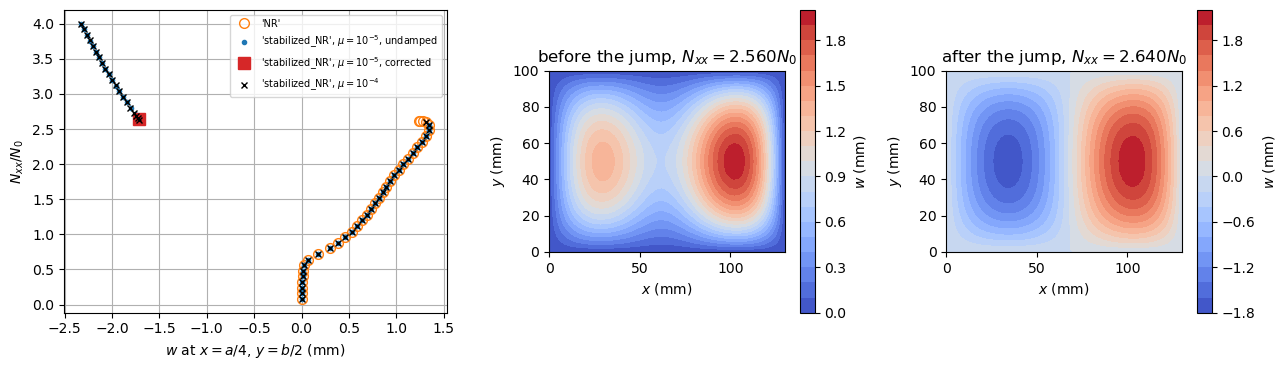

In [7]:
def wq(s, c):
    # deflection at x = a/4, y = b/2
    return s.uvw(c=c, gridx=5, gridy=3)[1]['w'][1, 1]


fig, axes = plt.subplots(1, 3, figsize=(13, 3.8),
                         gridspec_kw=dict(width_ratios=[1.3, 1, 1]))
ax = axes[0]
ax.plot([wq(s, c) for c in nr.cs], 4*np.asarray(nr.increments), 'o',
        color='C1', ms=7, mfc='none', label="'NR'")
markers = {'undamped': ('.', 'C0'), 'corrected': ('s', 'C3')}
for stat, (mk, col) in markers.items():
    pts = np.array([(wq(s, c), 4*l) for l, c, si
                    in zip(st.increments, st.cs, status) if si == stat])
    ax.plot(pts[:, 0], pts[:, 1], mk, color=col, ms=8 if mk == 's' else 6,
            label=r"'stabilized_NR', $\mu = 10^{-5}$, %s" % stat)
ax.plot([wq(s, c) for c in st4.cs], 4*np.asarray(st4.increments), 'x',
        color='k', ms=4, label=r"'stabilized_NR', $\mu = 10^{-4}$")
ax.set_xlabel('$w$ at $x = a/4$, $y = b/2$ (mm)')
ax.set_ylabel(r'$N_{xx}/N_0$')
ax.grid(True)
ax.legend(fontsize=7)
for ax, i, title in ((axes[1], ijump - 1, 'before the jump'),
                     (axes[2], ijump, 'after the jump')):
    pm, fields = s.uvw(c=st.cs[i], gridx=66, gridy=51)
    x, y = pm['Xs'], pm['Ys']
    cf = ax.contourf(x, y, fields['w'], levels=21, cmap='coolwarm')
    fig.colorbar(cf, ax=ax, label='$w$ (mm)')
    ax.set_aspect('equal')
    ax.set_xlabel('$x$ (mm)')
    ax.set_ylabel('$y$ (mm)')
    ax.set_title(r'%s, $N_{xx} = %.3f N_0$' % (title, 4*st.increments[i]))
plt.tight_layout()

Before the jump the deflection has one sign over the plate, with two crests of
different heights; after it, the two half-waves have opposite signs.

## A finer model

With $16 \times 14$ terms, the same analyses take a few minutes:

In [8]:
sf = plate(4*N0, m=16, n=14)
nrf, t_nrf = run(sf, 'NR')
stf, t_stf = run(sf, 'stabilized_NR')
print('NR: stops at the load factor %.5f, %d half-wave(s), %.1f s'
      % (nrf.increments[-1], half_waves(sf, nrf.cs[-1]), t_nrf))
print('stabilized_NR, mu = %g: %d increments, %.1f s, statuses %s'
      % (stf.stabilization_factor, len(stf.increments), t_stf,
         dict(Counter(stf.stabilization_status))))
print('at the reference load: %d half-wave(s), largest deflection %.4f mm '
      '(12 x 10 terms: %.4f mm)'
      % (half_waves(sf, stf.cs[-1]), wmax(sf, stf.cs[-1]),
         wmax(s, st.cs[-1])))

NR: stops at the load factor 0.65203, 1 half-wave(s), 83.9 s
stabilized_NR, mu = 1e-05: 50 increments, 104.7 s, statuses {'undamped': 49, 'corrected': 1}
at the reference load: 2 half-wave(s), largest deflection 3.1447 mm (12 x 10 terms: 3.1320 mm)


The limit point and the state at the reference load change little with the
finer model, and the jump is also passed with one `'corrected'` state.

## What the method does not guarantee

The stabilized method finds an equilibrium beyond the jump, not necessarily
the one a dynamic process would reach, and it does not check the stability
of the accepted states; with `Analysis.inertia = True` the inertia of the
tangent stiffness matrix is recorded at each accepted state. A `'damped'`
state, when the correction fails, is not an equilibrium: its stresses and
displacements must not be read as those of the plate.